# Thornquist Outfitters: Sales Dashboard
**Visualisation layer (QuickSight substitute).** QuickSight is not in the Learner Lab catalog, so this
notebook runs the same curated-layer SQL that analysts use (`sql/analytics/`) and charts the results.

* `MODE = "athena"`: runs on AWS through the `thornquist-wg` workgroup using boto3. Use SageMaker Studio Lab,
  a Glue notebook, or a laptop with Learner Lab credentials.
* `MODE = "local"`: runs on the Parquet output of `local/run_local.py` using DuckDB, with the same SQL and
  table names.

**Cost note:** a QuickSight Standard author costs about USD 9–24 per month plus SPICE capacity. This notebook
costs only the Athena bytes it scans, which is under 1 MB for the queries below (well below USD 0.01).

In [1]:
import os, time, glob
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

MODE = os.environ.get("TQ_MODE", "local")          # "athena" or "local"
BUCKET = os.environ.get("BUCKET", "<your-lake-bucket>")
WORKGROUP = "thornquist-wg"
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "dashboard" else os.getcwd()
SQL_DIR = os.path.join(ROOT, "sql", "analytics")
FIG_DIR = os.path.join(ROOT, "dashboard", "figures"); os.makedirs(FIG_DIR, exist_ok=True)

# Fixed colour per entity (validated categorical slots 1-2; colour follows the channel, never its rank)
STORE, ONLINE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
                     "legend.frameon": False})

if MODE == "local":
    import sys; sys.path.insert(0, os.path.join(ROOT, "local"))
    from run_local import register_duckdb
    con = register_duckdb(os.path.join(ROOT, "local_lake"))
    def run_sql(sql): return con.execute(sql).fetchdf()
else:
    import boto3
    athena = boto3.client("athena", region_name="us-east-1")
    def run_sql(sql):
        qid = athena.start_query_execution(QueryString=sql, WorkGroup=WORKGROUP)["QueryExecutionId"]
        while (st := athena.get_query_execution(QueryExecutionId=qid)["QueryExecution"]["Status"]["State"]) in ("QUEUED", "RUNNING"):
            time.sleep(1)
        if st != "SUCCEEDED":
            raise RuntimeError(athena.get_query_execution(QueryExecutionId=qid)["QueryExecution"]["Status"])
        return pd.read_csv(f"s3://{BUCKET}/athena-results/{qid}.csv")   # needs s3fs; or use get_query_results

def q(name):
    return run_sql(open(os.path.join(SQL_DIR, name + ".sql")).read())

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), bbox_inches="tight", facecolor="white")
print("mode:", MODE)

mode: local


## Headline KPIs (week of 24–30 Aug 2026)

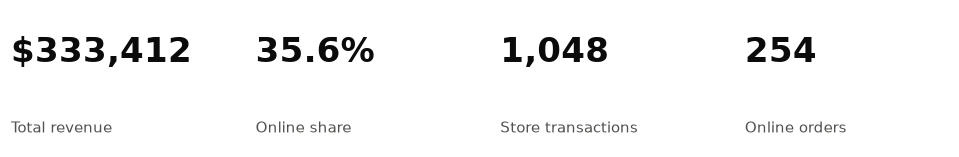

In [2]:
kpi = run_sql('''
SELECT channel, COUNT(DISTINCT order_id) AS orders, SUM(CAST(line_revenue AS DOUBLE)) AS revenue
FROM thornquist_curated.fact_sales WHERE sale_date BETWEEN '2026-08-24' AND '2026-08-30' GROUP BY channel''')
tot = kpi.revenue.sum()
online = kpi.loc[kpi.channel != 'store', 'revenue'].sum()
tiles = [("Total revenue", f"${tot:,.0f}"), ("Online share", f"{online/tot:.1%}"),
         ("Store transactions", f"{int(kpi.loc[kpi.channel=='store','orders'].sum()):,}"),
         ("Online orders", f"{int(kpi.loc[kpi.channel!='store','orders'].sum()):,}")]
fig, axes = plt.subplots(1, 4, figsize=(11, 1.6))
for ax, (label, value) in zip(axes, tiles):
    ax.axis("off"); ax.text(0, 0.62, value, fontsize=22, weight="bold", color=INK); ax.text(0, 0.1, label, color=MUTED)
save(fig, "00_kpis"); plt.show()

## 1 · Revenue by region and channel
Which regions drive revenue, and how dependent each is on stores (Q1).

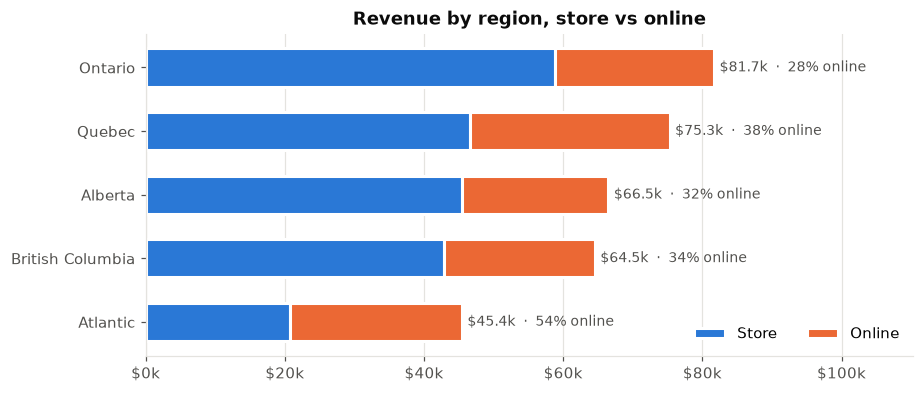

,region,store_revenue,online_revenue,total_revenue,online_share_pct,share_of_company_pct
0,Ontario,58817.06,22858.10,81675.16,28.0,24.5
1,Quebec,46653.40,28628.85,75282.25,38.0,22.6
2,Alberta,45447.91,21034.33,66482.24,31.6,19.9
3,British Columbia,42863.23,21673.66,64536.89,33.6,19.4
4,Atlantic,20780.18,24655.00,45435.18,54.3,13.6


In [3]:
r = q("q01_revenue_by_channel_region").sort_values("total_revenue")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(r.region, r.store_revenue, color=STORE, height=0.6, label="Store", edgecolor="white", linewidth=2)
ax.barh(r.region, r.online_revenue, left=r.store_revenue, color=ONLINE, height=0.6, label="Online", edgecolor="white", linewidth=2)
for y, (t, s) in enumerate(zip(r.total_revenue, r.online_share_pct)):
    ax.text(t + 800, y, f"${t/1000:,.1f}k  ·  {s:.0f}% online", va="center", color=MUTED, fontsize=9)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:.0f}k")); ax.grid(axis="y", visible=False)
ax.set_xlim(0, r.total_revenue.max() * 1.35); ax.set_title("Revenue by region, store vs online")
ax.legend(loc="lower right", ncol=2); save(fig, "01_region_channel"); plt.show()
r.sort_values("total_revenue", ascending=False)

## 2 · Category mix by channel (Q2)

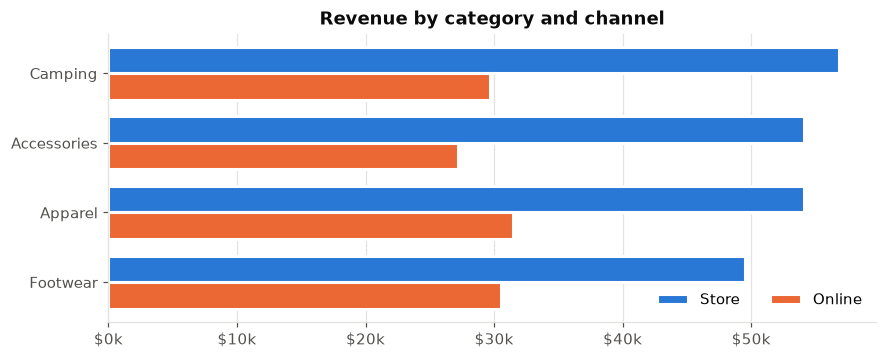

,category,channel,units,revenue,avg_selling_price,pct_of_channel_revenue
0,Apparel,online,185.0,31501.92,170.28,26.5
1,Footwear,online,175.0,30499.15,174.28,25.7
2,Camping,online,172.0,29653.23,172.40,25.0
3,Accessories,online,166.0,27195.64,163.83,22.9
4,Camping,store,337.0,56840.08,168.66,26.5
5,Accessories,store,325.0,54127.67,166.55,25.2
6,Apparel,store,305.0,54094.57,177.36,25.2
7,Footwear,store,284.0,49499.46,174.29,23.1


In [4]:
c = q("q02_category_by_channel")
p = c.pivot(index="category", columns="channel", values="revenue").sort_values("store")
fig, ax = plt.subplots(figsize=(9, 3.4)); h = 0.38; y = range(len(p))
ax.barh([i + h/2 for i in y], p["store"], h, color=STORE, label="Store", edgecolor="white", linewidth=2)
ax.barh([i - h/2 for i in y], p["online"], h, color=ONLINE, label="Online", edgecolor="white", linewidth=2)
ax.set_yticks(list(y)); ax.set_yticklabels(p.index); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
ax.set_title("Revenue by category and channel"); ax.legend(loc="lower right", ncol=2)
save(fig, "02_category_channel"); plt.show(); c

## 3 · Daily revenue trend (Q3)

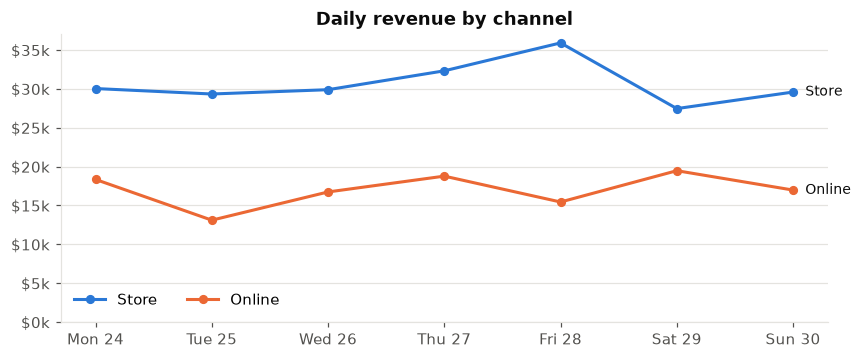

,sale_date,channel,orders,revenue,dod_growth_pct
0,2026-08-24,online,40,18343.32,NaN
1,2026-08-25,online,29,13105.11,-28.6
2,2026-08-26,online,31,16736.87,27.7
3,2026-08-27,online,36,18771.77,12.2
4,2026-08-28,online,38,15442.96,-17.7
5,2026-08-29,online,42,19471.77,26.1
6,2026-08-30,online,38,16978.14,-12.8
7,2026-08-24,store,140,30040.93,NaN
8,2026-08-25,store,159,29339.39,-2.3
9,2026-08-26,store,134,29893.65,1.9


In [5]:
d = q("q03_daily_trend_growth"); d["sale_date"] = pd.to_datetime(d.sale_date)
fig, ax = plt.subplots(figsize=(9, 3.4))
for ch, col, lab in (("store", STORE, "Store"), ("online", ONLINE, "Online")):
    s = d[d.channel == ch]
    ax.plot(s.sale_date, s.revenue, color=col, lw=2, marker="o", ms=5, label=lab)
    ax.annotate(lab, (s.sale_date.iloc[-1], s.revenue.iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color=INK, fontsize=9)
ax.set_ylim(0); ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a %d")); ax.grid(axis="x", visible=False)
ax.set_title("Daily revenue by channel"); ax.legend(loc="lower left", ncol=2)
save(fig, "03_daily_trend"); plt.show(); d

## 4 · Customer-segment insight: loyalty tier × channel (Q4)
This blends the legacy customer extract with sales from both channels.

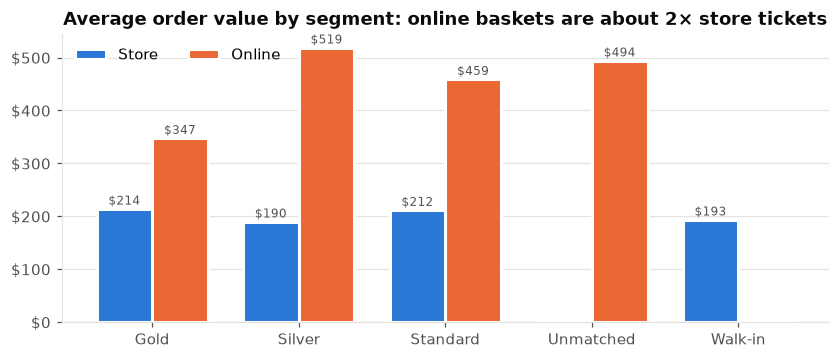

,customer_segment,channel,customers,orders,revenue,avg_order_value,units_per_order,revenue_per_customer
0,Gold,online,11,17,5906.61,347.45,2.12,536.96
1,Gold,store,35,82,17548.37,214.00,1.18,501.38
2,Silver,online,37,50,25928.48,518.57,3.20,700.77
3,Silver,store,71,183,34693.62,189.58,1.16,488.64
4,Standard,online,124,154,70707.79,459.14,2.66,570.22
5,Standard,store,247,598,126546.90,211.62,1.21,512.34
6,Unmatched,online,28,33,16307.06,494.15,2.82,582.40
7,Walk-in,store,0,185,35772.89,193.37,1.19,NaN


In [6]:
s = q("q04_segment_channel_behaviour")
order = ["Gold", "Silver", "Standard", "Unmatched", "Walk-in"]
p = s.pivot(index="customer_segment", columns="channel", values="avg_order_value").reindex(order)
fig, ax = plt.subplots(figsize=(9, 3.4)); w = 0.38; x = range(len(p))
ax.bar([i - w/2 for i in x], p["store"].fillna(0), w, color=STORE, label="Store", edgecolor="white", linewidth=2)
ax.bar([i + w/2 for i in x], p["online"].fillna(0), w, color=ONLINE, label="Online", edgecolor="white", linewidth=2)
for i, (a, b) in enumerate(zip(p["store"], p["online"])):
    if pd.notna(b): ax.text(i + w/2, b + 8, f"${b:,.0f}", ha="center", fontsize=8, color=MUTED)
    if pd.notna(a): ax.text(i - w/2, a + 8, f"${a:,.0f}", ha="center", fontsize=8, color=MUTED)
ax.set_xticks(list(x)); ax.set_xticklabels(order); ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v:.0f}"))
ax.set_title("Average order value by segment: online baskets are about 2× store tickets"); ax.legend(ncol=2)
save(fig, "04_segment_aov"); plt.show(); s

## 5 · Omnichannel customers are worth more (Q5)

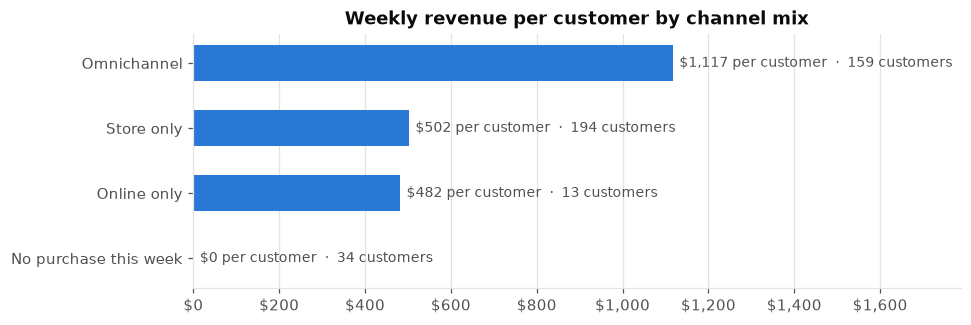

,channel_mix,customers,pct_of_customers,gold_customers,revenue,revenue_per_customer,orders_per_customer,label
0,1 - Omnichannel,159,39.8,10.0,177628.71,1117.16,3.77,Omnichannel
1,2 - Store only,194,48.5,25.0,97442.19,502.28,2.41,Store only
2,3 - Online only,13,3.3,1.0,6260.87,481.61,1.31,Online only
3,4 - No purchase this week,34,8.5,4.0,0.00,0.00,0.00,No purchase this week


In [7]:
o = q("q05_omnichannel_customers"); o["label"] = o.channel_mix.str[4:]
fig, ax = plt.subplots(figsize=(9, 3.0))
ax.barh(o.label[::-1], o.revenue_per_customer[::-1], color=STORE, height=0.55)
for y, (v, n) in enumerate(zip(o.revenue_per_customer[::-1], o.customers[::-1])):
    ax.text(v + 15, y, f"${v:,.0f} per customer  ·  {n} customers", va="center", color=MUTED, fontsize=9)
ax.set_xlim(0, o.revenue_per_customer.max() * 1.6); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_title("Weekly revenue per customer by channel mix")
save(fig, "05_omnichannel"); plt.show(); o

## 6 · Store league table and walk-in rate (Q7) · Data trust (Q8)

In [8]:
st = q("q07_store_customer_capture"); display(st)
display(q("q08_data_trust_exposure"))
display(q("q06_demand_vs_allocation"))

,store_id,store_name,region,transactions,revenue,avg_ticket,walk_in_pct,revenue_rank
0,1,Toronto Yonge St,Ontario,105,23628.54,225.03,18.1,1
1,7,Victoria Douglas,British Columbia,118,23591.13,199.92,19.5,2
2,4,Montreal Ste-Catherine,Quebec,109,23431.18,214.96,15.6,3
3,5,Quebec City Laurier,Quebec,119,23222.22,195.14,17.6,4
4,9,Edmonton Whyte Ave,Alberta,112,22895.06,204.42,17.9,5
5,8,Calgary Stephen Ave,Alberta,109,22552.85,206.91,19.3,6
6,10,Halifax Spring Garden,Atlantic,107,20780.18,194.21,18.7,7
7,6,Vancouver Robson,British Columbia,98,19272.10,196.65,21.4,8
8,2,Toronto Scarborough,Ontario,88,18227.66,207.13,13.6,9
9,3,Ottawa Rideau,Ontario,83,16960.86,204.35,13.3,10


,channel,orders,orphan_orders,orphan_customer_ids,orphan_revenue,orphan_revenue_pct,walk_in_revenue_pct
0,online,260,34,28,17375.22,14.1,0.0
1,store,1048,0,0,0.00,0.0,16.7


,region,demand_rank,product_name,category,units,online_units,online_share_pct
0,Alberta,1,Alpine Hiking Shoe,Footwear,34.0,10.0,29.4
1,Alberta,2,Sleeping Bag -10C,Camping,34.0,6.0,17.6
2,Alberta,3,Hydration Pack,Accessories,29.0,4.0,13.8
3,Atlantic,1,Insulated Winter Boot,Footwear,22.0,16.0,72.7
4,Atlantic,2,Sleeping Bag -10C,Camping,20.0,9.0,45.0
5,Atlantic,3,Trail Runner Low,Footwear,20.0,13.0,65.0
6,British Columbia,1,2-Person Tent,Camping,32.0,8.0,25.0
7,British Columbia,2,Insulated Winter Boot,Footwear,25.0,9.0,36.0
8,British Columbia,3,Merino Base Layer,Apparel,25.0,7.0,28.0
9,Ontario,1,Fleece Pullover,Apparel,42.0,14.0,33.3


## Key findings
1. **Ontario leads revenue** at about a quarter of the company total. **Atlantic is the outlier**: more than
   half its revenue is online because it has only one store (Halifax). That points to a case for a second
   Atlantic store or faster regional fulfilment.
2. **Online baskets are about 2× the value of store tickets** in every loyalty tier (more items per order).
   Silver customers are the highest-value online shoppers.
3. **Omnichannel customers** (about 40 % of the customer base) generate roughly **2.2× the weekly revenue** of
   store-only customers. Cross-channel loyalty marketing is the lever.
4. **Data trust:** 14 % of online revenue comes from orders whose customer ID is missing from the master
   extract, and 17 % of store revenue is anonymous walk-ins. Segment metrics should be read with that coverage
   in mind. Fixing the customer-master sync is the top data-quality action.